# A tour of the Synthetic Football League

Work through this top to bottom. Each section covers one way into the data and shows the pandas you'll reuse in the app.

**Setup:** open the project folder in VS Code, choose the Python interpreter from your venv, then **Run All**. It needs `pandas` and `matplotlib` (`pip install -r requirements.txt`).

One rule to remember: every event's `x`/`y` is from the point of view of **the team doing it, attacking left to right**. `x = 105` is the goal they are attacking.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

D = Path("../data") if Path("../data").exists() else Path("data")
events  = pd.read_csv(D / "events.csv.gz")
matches = pd.read_csv(D / "matches.csv")
clubs   = pd.read_csv(D / "clubs.csv").set_index("club_id")
players = pd.read_csv(D / "players.csv").set_index("player_id")
poss    = pd.read_csv(D / "possessions.csv.gz")
tms     = pd.read_csv(D / "team_match_stats.csv")
pms     = pd.read_csv(D / "player_match_stats.csv")
table   = pd.read_csv(D / "standings.csv")

name = clubs["short_name"]
pname = players["name"]
print(f"{len(matches)} matches, {len(events):,} events, {len(poss):,} possessions, {len(players)} players")
events.head(3)

380 matches, 567,499 events, 102,035 possessions, 500 players


,match_id,event_id,period,clock_s,period_s,minute,display_clock,team_id,player_id,type,...,body_part,shot_type,xg,set_piece,card,possession_id,possession_team_id,score_home,score_away,tags
0,M001,1,1,0.0,0.0,0,1',NaN,NaN,period_start,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN
1,M001,2,1,0.0,0.0,0,1',FER,P0478,pass,...,NaN,NaN,NaN,kickoff,NaN,1.0,FER,0,0,NaN
2,M001,3,1,2.0,2.0,0,1',FER,P0490,carry,...,NaN,NaN,NaN,NaN,NaN,1.0,FER,0,0,NaN


## 1. The world

Twenty fictional clubs. Each has a playing **style** and **formation**, and these really do change how it plays (section 6 shows it).

In [2]:
clubs[["name", "city", "stadium", "style", "formation"]]

,name,city,stadium,style,formation
club_id,,,,,
COR,Corriemoor City,Corriemoor,The Citadel,possession,4-3-3
RAV,Ravensholt Athletic,Ravensholt,Ravensholt Park,high_press,4-3-3
DUN,Dunhallow United,Dunhallow,Old Quarry Road,counter,4-2-3-1
NGH,Northgate Harriers,Northgate,Harrier Lane,balanced,4-2-3-1
GLE,Glenmarrow,Glenmarrow,The Marrow,high_press,4-2-3-1
KES,Kestrel Bay,Kestrel Bay,Cliffside Stadium,wing_play,4-3-3
QUE,Queensreach Rangers,Queensreach,Crown Meadow,wing_play,4-3-3
HAR,Hartsmere Vale,Hartsmere,Vale Park Road,possession,4-3-3
OAK,Oakhurst Sporting,Oakhurst,The Acorn,possession,3-4-3


## 2. The final table, and who was lucky

Points measure results. **xG difference** measures how good a side actually was at creating and preventing chances. The gap between the two is luck, and that's a ready-made storyline.

In [3]:
t = table[["position", "club", "club_id", "points", "goals_for", "goals_against", "xg_for", "xg_against"]].copy()
t["gd"]  = t.goals_for - t.goals_against
t["xgd"] = (t.xg_for - t.xg_against).round(1)
t["finishing_luck"] = (t.gd - t.xgd).round(1)          # + scored/conceded better than chances deserved
t.set_index("position")

,club,club_id,points,goals_for,goals_against,xg_for,xg_against,gd,xgd,finishing_luck
position,,,,,,,,,,
1,Ravensholt Athletic,RAV,82,71,28,78.34,32.12,43,46.2,-3.2
2,Corriemoor City,COR,82,70,27,71.31,36.69,43,34.6,8.4
3,Dunhallow United,DUN,78,81,38,85.76,39.39,43,46.4,-3.4
4,Northgate Harriers,NGH,72,59,37,64.83,40.87,22,24.0,-2.0
5,Eskmouth Wanderers,ESK,59,67,52,55.38,49.69,15,5.7,9.3
6,Glenmarrow,GLE,58,53,44,68.16,48.50,9,19.7,-10.7
7,Kestrel Bay,KES,58,56,54,58.80,53.43,2,5.4,-3.4
8,Hartsmere Vale,HAR,55,51,54,45.79,55.49,-3,-9.7,6.7
9,Ashcombe Rovers,ASH,52,49,50,47.01,54.19,-1,-7.2,6.2


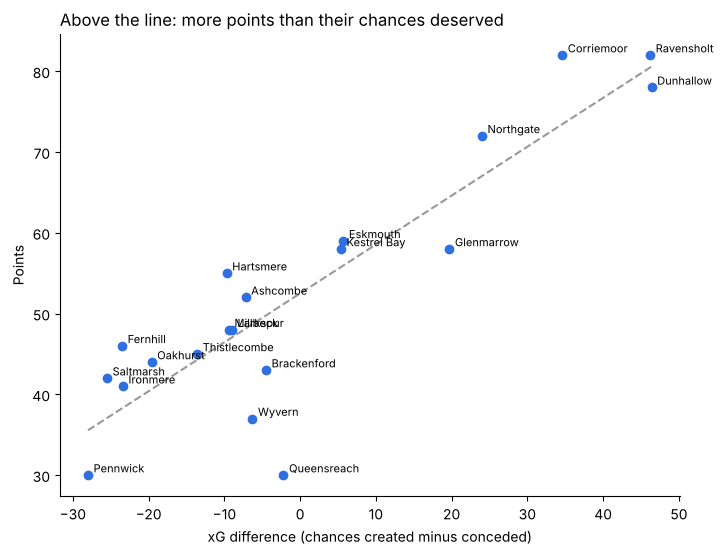

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(t.xgd, t.points, color="#2f6fdf")
for r in t.itertuples():
    ax.annotate(name[r.club_id], (r.xgd, r.points), fontsize=8, xytext=(4, 2), textcoords="offset points")
m, b = np.polyfit(t.xgd, t.points, 1)
xs = np.linspace(t.xgd.min(), t.xgd.max(), 10)
ax.plot(xs, m * xs + b, "--", color="#999")
ax.set_xlabel("xG difference (chances created minus conceded)")
ax.set_ylabel("Points")
ax.set_title("Above the line: more points than their chances deserved", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Ground truth: can you tell skill from luck?

`ground_truth_club_ratings.csv` holds each club's **true** strength, the numbers the engine used. Real analysts never get this. You can use it to *prove* your insights are right. Here, xG difference tracks true strength better than points or goal difference does.

In [5]:
truth = pd.read_csv(D / "ground_truth_club_ratings.csv").set_index("club_id")
truth["true_strength"] = np.log(truth.attack_rating / truth.defence_rating)
t2 = t.set_index("club_id").join(truth)
for col in ["points", "gd", "xgd"]:
    print(f"correlation with true strength - {col:>6}: {t2[col].corr(t2.true_strength):.3f}")

correlation with true strength - points: 0.827
correlation with true strength -     gd: 0.857
correlation with true strength -    xgd: 0.921


## 3. One match, event by event

Match IDs run M001 to M380. **M059**, Eskmouth 4-3 Dunhallow, is a good one: the underdog wins despite creating less. Replay it in the terminal too: `python scripts/replay.py M059`.

In [6]:
MID = "M059"
m = matches.set_index("match_id").loc[MID]
e = events[events.match_id == MID].sort_values("event_id")
print(f"{clubs.loc[m.home_id, 'name']} {m.home_goals}-{m.away_goals} {clubs.loc[m.away_id, 'name']}  (xG {m.home_xg}-{m.away_xg})")
print(e.type.value_counts().head(8).to_dict())

key = e[e.type.isin(["shot", "card", "substitution", "penalty_awarded"])].copy()
key["team"] = key.team_id.map(name)
key["player"] = key.player_id.map(pname)
key[["display_clock", "team", "player", "type", "outcome", "card", "xg", "score_home", "score_away"]].head(20)

Eskmouth Wanderers 4-3 Dunhallow United  (xG 1.182-2.056)
{'pass': 945, 'carry': 112, 'ball_recovery': 111, 'take_on': 69, 'clearance': 39, 'interception': 38, 'tackle': 26, 'shot': 24}


,display_clock,team,player,type,outcome,card,xg,score_home,score_away
86258,1',Eskmouth,Morgan Marsden,shot,goal,NaN,0.3049,1,0
86269,3',Dunhallow,Adrien Dufour,shot,saved,NaN,0.0141,1,0
86290,3',Dunhallow,Duarte Carvalhal,shot,blocked,NaN,0.0743,1,0
86302,4',Dunhallow,Adrien Dufour,shot,off_target,NaN,0.2617,1,0
86384,10',Dunhallow,Adrien Dufour,shot,off_target,NaN,0.2358,1,0
86397,11',Dunhallow,Adrien Dufour,shot,blocked,NaN,0.0096,1,0
86487,17',Dunhallow,Adrien Dufour,shot,goal,NaN,0.1003,1,1
86507,20',Dunhallow,Unai Ortega,shot,off_target,NaN,0.5091,1,1
86534,22',Dunhallow,Adrien Dufour,shot,off_target,NaN,0.0268,1,1
86567,24',Eskmouth,Morgan Marsden,shot,goal,NaN,0.1212,2,1


### The xG race

Cumulative xG over the match, with goals marked. This is the most useful single chart for "did they deserve it?" narratives.

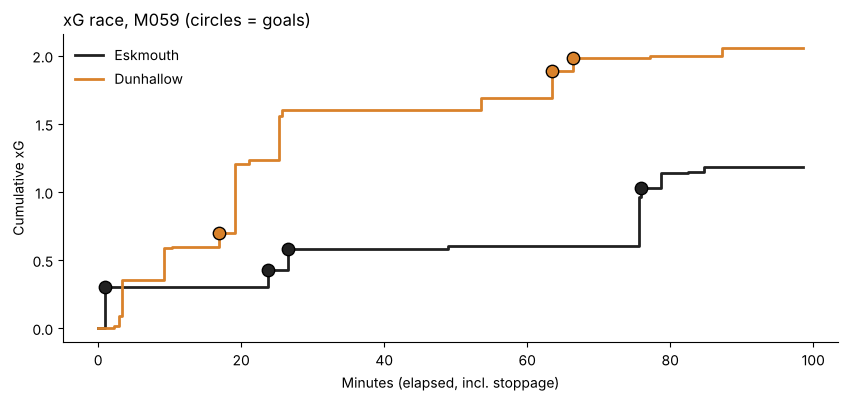

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for cid, col in ((m.home_id, clubs.loc[m.home_id, "primary_colour"]), (m.away_id, "#d9822b")):
    s = e[(e.team_id == cid) & (e.type == "shot")]
    tmin = np.concatenate([[0], s.clock_s / 60, [e.clock_s.max() / 60]])
    cum = np.concatenate([[0], s.xg.cumsum(), [s.xg.sum()]])
    ax.step(tmin, cum, where="post", label=name[cid], color=col, linewidth=2)
    g = s[s.outcome == "goal"]
    ax.scatter(g.clock_s / 60, s.xg.cumsum()[s.outcome == "goal"], color=col, s=80, zorder=3, edgecolor="black")
ax.set_xlabel("Minutes (elapsed, incl. stoppage)")
ax.set_ylabel("Cumulative xG")
ax.set_title(f"xG race, {MID} (circles = goals)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Where things happen: shot maps

The pitch is 105 × 68 m. Shots are already in attacking direction, so every team's shots point at the goal on the right.

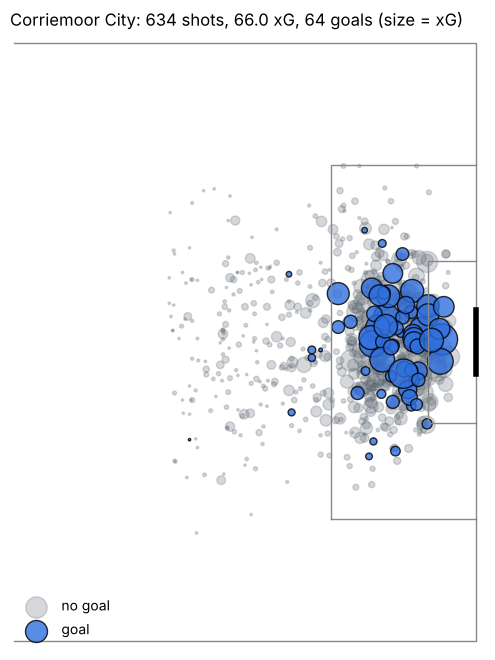

In [8]:
def pitch(ax):
    ax.set_xlim(52, 106); ax.set_ylim(-1, 69); ax.set_aspect("equal"); ax.axis("off")
    ax.plot([52.5, 105, 105, 52.5], [0, 0, 68, 68], color="#888", lw=1)
    ax.plot([88.5, 88.5, 105], [13.84, 54.16, 54.16], color="#888", lw=1); ax.plot([88.5, 105], [13.84, 13.84], color="#888", lw=1)
    ax.plot([99.5, 99.5, 105], [24.84, 43.16, 43.16], color="#888", lw=1); ax.plot([99.5, 105], [24.84, 24.84], color="#888", lw=1)
    ax.plot([105, 105], [30.34, 37.66], color="black", lw=4)

CLUB = "COR"
s = events[(events.team_id == CLUB) & (events.type == "shot") & (events.shot_type != "penalty")]
fig, ax = plt.subplots(figsize=(7, 8)); pitch(ax)
miss = s[s.outcome != "goal"]; goal = s[s.outcome == "goal"]
ax.scatter(miss.x, miss.y, s=miss.xg * 600, alpha=0.25, color="#59636e", label="no goal")
ax.scatter(goal.x, goal.y, s=goal.xg * 600, alpha=0.8, color="#2f6fdf", edgecolor="black", label="goal")
ax.set_title(f"{clubs.loc[CLUB, 'name']}: {len(s)} shots, {s.xg.sum():.1f} xG, {len(goal)} goals (size = xG)", loc="left")
ax.legend(loc="lower left", frameon=False)
plt.show()

## 5. Players

`player_match_stats.csv` has one row per player per match. Summing over the season gives the usual leaderboards. Goals minus xG shows who finished well and who didn't.

In [9]:
season = pms.groupby("player_id")[["minutes", "goals", "xg", "assists", "xa", "key_passes", "shots"]].sum()
season = season.join(players[["name", "club_id", "primary_role", "age", "nationality"]])
season["goals_minus_xg"] = (season.goals - season.xg).round(1)
season["xg_per90"] = (season.xg / season.minutes * 90).round(2)
season.sort_values("goals", ascending=False).head(10)[
    ["name", "club_id", "primary_role", "goals", "xg", "goals_minus_xg", "assists", "xa", "minutes"]].round(1)

,name,club_id,primary_role,goals,xg,goals_minus_xg,assists,xa,minutes
player_id,,,,,,,,,
P0071,Adrien Dufour,DUN,ST,29,28.1,0.9,9,11.9,3210.2
P0319,Morgan Marsden,ESK,RST,25,16.9,8.1,6,6.5,3053.9
P0421,Gonçalo Pinheiro,MIL,LST,23,22.2,0.8,8,6.1,3095.8
P0296,Ben Rushworth,LAR,LST,19,14.7,4.3,4,5.2,3305.4
P0019,Hugo Lemaire,COR,ST,19,20.1,-1.1,15,11.2,3032.5
P0192,Kieran Denholm,HAR,RW,18,17.1,0.9,4,3.1,3318.6
P0269,Facundo Quiroga,ASH,RST,18,17.2,0.8,10,7.2,3335.6
P0046,Kasper Kjær,RAV,LW,16,14.3,1.7,13,11.9,3224.7
P0346,Jack Calloway,BRB,LST,16,12.9,3.1,10,5.9,2566.3


## 6. Does style show up in the data?

Each club was given a style, and the engine never wrote these stats down directly. They emerge from how the matches play out. If the data is good, possession sides should pass more, pressing sides should have a low PPDA (passes the opponent gets per defensive action) and win the ball high, and counter sides should break quickly.

In [10]:
pat = poss.groupby(["team_id", "pattern"]).size().unstack(fill_value=0)
style = tms.groupby("club_id")[["possession_pct", "pass_accuracy", "ppda", "crosses", "high_turnovers", "counter_attacks"]].mean()
style = style.join(clubs[["style"]]).groupby("style").mean().round(2)
style.sort_values("possession_pct", ascending=False)

,possession_pct,pass_accuracy,ppda,crosses,high_turnovers,counter_attacks
style,,,,,,
possession,59.38,0.87,11.03,10.56,13.96,5.31
high_press,54.74,0.83,9.39,13.58,19.38,12.15
wing_play,50.71,0.81,10.63,14.54,18.43,11.18
balanced,50.03,0.80,10.47,12.39,18.99,11.82
counter,45.85,0.76,11.21,12.35,21.36,17.70
direct,40.67,0.69,10.67,13.35,23.06,17.25


## 7. Possessions: the unit of a story

Every event belongs to a possession, and each possession has a label. Here is a club's most dangerous counter-attack, rebuilt event by event, which is exactly what a commentary agent would narrate.

In [11]:
c = poss[(poss.pattern == "counter_attack") & poss.goal].sort_values("duration_s").iloc[0]
seq = events[(events.match_id == c.match_id) & (events.possession_id == c.possession_id)].copy()
seq["player"] = seq.player_id.map(pname)
print(f"{c.match_id}: {name[c.team_id]} counter, won the ball at x={c.start_x}, {c.passes} passes, {c.duration_s}s, xG {c.xg}")
seq[["display_clock", "player", "type", "outcome", "x", "y", "end_x", "end_y", "pass_type", "xg"]]

M202: Wyvern counter, won the ball at x=46.9, 2 passes, 6.4s, xG 0.0747


,display_clock,player,type,outcome,x,y,end_x,end_y,pass_type,xg
300420,38',Ryan Kettering,pass,complete,46.9,41.4,69.6,36.1,short,NaN
300421,38',Vitinha Teixeira,pass,complete,70.7,33.0,93.7,26.1,through_ball,NaN
300422,38',Quentin Rousseau,shot,goal,93.7,26.1,105.0,36.3,NaN,0.0747


## 8. Questions to try next

- Which side scores most from set pieces (`shot_type == "set_piece"` or `set_piece == "corner"`)?
- Who drops points from winning positions? (`score_home`/`score_away` on each goal event, plus the final result.)
- How does a red card change a match? Compare xG per minute before and after `card in ("red", "second_yellow")`.
- The title race: plot `standings_by_matchweek.csv` positions for the top 4 across 38 matchweeks.

Column definitions are in `docs/SCHEMA.md`.